# Análisis inicial de pedidos de e-commerce

## Necesidad y pregunta

Se necesita describir los pedidos disponibles para conocer la información sobre compras, clientes, pagos y entregas antes de realizar análisis comerciales. La pregunta inicial es: **¿qué características tienen los pedidos y qué variables permiten estudiar el comportamiento de compra y la operación de entrega?**

Cada fila representa un pedido. `category`, `price` y `quantity` describen la compra; las fechas y `delivery_status` describen la entrega; y `payment_method`, `device_type`, `channel` y `customer_segment` permiten explorar el comportamiento del cliente.

El alcance de esta entrega es obtener el dataset, revisar su estructura y calidad, exportar los datos a CSV y generar un resumen reproducible en formato `.txt`.


In [70]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [71]:
hfdataset = HFDatasetLoader(dataset_name="millat/e-commerce-orders", split="train", filename="datos/e-commerce-orders.csv")

In [72]:
df = hfdataset.load()

In [73]:
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas")
df.info()
display(df.describe(include="all").transpose().head(15))


Dimensiones: 10000 filas y 15 columnas
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          10000 non-null  str    
 1   customer_id       10000 non-null  int64  
 2   product_id        10000 non-null  int64  
 3   category          10000 non-null  str    
 4   price             10000 non-null  float64
 5   quantity          10000 non-null  int64  
 6   order_date        10000 non-null  str    
 7   shipping_date     10000 non-null  str    
 8   delivery_status   10000 non-null  str    
 9   payment_method    10000 non-null  str    
 10  device_type       10000 non-null  str    
 11  channel           10000 non-null  str    
 12  shipping_address  10000 non-null  str    
 13  billing_address   10000 non-null  str    
 14  customer_segment  10000 non-null  str    
dtypes: float64(1), int64(3), str(11)
memory usage: 3.4 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,10000,10000,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,10000.0,NaN,NaN,NaN,995.2923,893.279854,1.0,182.0,754.0,1668.5,2999.0
product_id,10000.0,NaN,NaN,NaN,504.8724,288.281942,1.0,260.0,507.0,752.0,1000.0
category,10000,6,Home,1713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,10000.0,NaN,NaN,NaN,252.550681,141.394146,5.06,130.6075,252.91,374.9175,499.93
quantity,10000.0,NaN,NaN,NaN,2.1247,1.254315,1.0,1.0,2.0,3.0,9.0
order_date,10000,365,2025-04-01 14:59:58.897063,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_date,10000,371,2024-12-05 14:59:58.897063,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_status,10000,4,Delivered,7047,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,10000,5,Apple Pay,2068,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [74]:
df = hfdataset.load()
df.head(2)

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning


In [75]:
from clases_po import Reportes

In [76]:
reportes = Reportes()
texto = reportes.generar_reporte(df)

print(texto)

REPORTE DEL DATAFRAME
Filas: 10000
Columnas: 15
Duplicados: 0

Columnas y tipos:
- order_id: str
- customer_id: int64
- product_id: int64
- category: str
- price: float64
- quantity: int64
- order_date: str
- shipping_date: str
- delivery_status: str
- payment_method: str
- device_type: str
- channel: str
- shipping_address: str
- billing_address: str
- customer_segment: str

Valores nulos por columna:
- order_id: 0
- customer_id: 0
- product_id: 0
- category: 0
- price: 0
- quantity: 0
- order_date: 0
- shipping_date: 0
- delivery_status: 0
- payment_method: 0
- device_type: 0
- channel: 0
- shipping_address: 0
- billing_address: 0
- customer_segment: 0

Estadísticas numéricas:
       customer_id  product_id      price   quantity
count    10000.000   10000.000  10000.000  10000.000
mean       995.292     504.872    252.551      2.125
std        893.280     288.282    141.394      1.254
min          1.000       1.000      5.060      1.000
25%        182.000     260.000    130.608      

In [77]:
ruta = reportes.guardar_reporte(
    df,
    "reportes/E-commerce Orders & Customer Behavior.txt",
)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: reportes\E-commerce Orders & Customer Behavior.txt


In [78]:
ruta_reporte = ROOT / "src" / "sincronicas" / "reportes" / "E-commerce Orders & Customer Behavior.txt"
contenido_reporte = ruta_reporte.read_text(encoding="utf-8")
assert f"Filas: {len(df)}" in contenido_reporte
assert f"Columnas: {len(df.columns)}" in contenido_reporte
assert "Valores nulos por columna:" in contenido_reporte
print(f"Reporte verificado: {ruta_reporte} ({len(contenido_reporte)} caracteres)")


Reporte verificado: C:\Users\Usuario\Documents\Developers\PI3_2026Q4_Mary_Santi_Esteban\src\sincronicas\reportes\E-commerce Orders & Customer Behavior.txt (1226 caracteres)


---
# PARTE 2 - Preprocesamiento y estandarizacion

En esta parte se prepara el dataset de pedidos de e-commerce. Se conservan las columnas originales y se agregan variables calculadas para estudiar ventas, pedidos, clientes y entregas. La clase `PreprocesadorEcommerce` cumple el papel de las hojas Tipos y Datos trabajadas en clase.

## 2.1 Diagnostico de tipos

Antes de transformar los datos se revisan tipos, valores no vacios y conversiones numericas.

In [79]:
from IPython.display import display
import pandas as pd
from clases_po import PreprocesadorEcommerce, EnriquecedorEcommerce, AnalisisBase, AnalisisEcommerce, GraficosEcommerce

pre = PreprocesadorEcommerce()
df_base = pre.recortar(df)
display(pre.diagnosticar(df_base))

,columna,tipo_actual,ejemplo,no_vacíos (CONTARA),convertibles_a_número,¿es número? (ESNUMERO)
0,order_id,str,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,10000,0,False
1,customer_id,int64,2031,10000,10000,True
2,product_id,int64,845,10000,10000,True
3,category,str,Books,10000,0,False
4,price,float64,45.95,10000,10000,True
5,quantity,int64,4,10000,10000,True
6,order_date,str,2024-04-20 14:59:58.897063,10000,0,False
7,shipping_date,str,2024-04-27 14:59:58.897063,10000,0,False
8,delivery_status,str,Shipped,10000,0,False
9,payment_method,str,PayPal,10000,0,False


## 2.2 Diccionario de columnas

El diccionario relaciona cada campo del dataset con su significado y tipo estadistico. Esto permite justificar el nivel de detalle utilizado en las preguntas de negocio.

In [80]:
display(pre.diccionario())

,columna,qué significa,tipo de variable,tipo en pandas
0,order_id,Identificador único del pedido,Cualitativa nominal,string
1,customer_id,Identificador del cliente,Cuantitativa discreta,int64
2,product_id,Identificador del producto,Cuantitativa discreta,int64
3,quantity,Cantidad de unidades,Cuantitativa discreta,int64
4,order_date,Fecha y hora del pedido,Cuantitativa (tiempo),datetime64
5,shipping_date,Fecha y hora del envío,Cuantitativa (tiempo),datetime64
6,price,Precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
7,order_value,Cantidad × precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
8,device_type,Dispositivo utilizado,Cualitativa nominal,category
9,category,Categoría del producto,Cualitativa nominal,category


## 2.3 Conversion de tipos y columnas calculadas

Se convierten identificadores, cantidades, precios y fechas. Tambien se calculan `order_value`, `shipping_days`, `total_calculado`, `verificacion`, `dia_semana`, `hora` y `nuevo_pedido`.

In [81]:
datos_base = pre.procesar(df)
datos_base.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment,order_time,fecha_hora,shipping_days,order_value,total_calculado,verificacion,dia_semana,hora,nuevo_pedido
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,183.80,183.80,OK,sábado,14,1
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,2.0,1209.51,1209.51,OK,sábado,14,1
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,634.90,634.90,OK,sábado,14,1
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,4.0,72.24,72.24,OK,sábado,14,1
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,5.0,494.90,494.90,OK,sábado,14,1


In [82]:
datos_base.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          10000 non-null  string        
 1   customer_id       10000 non-null  Int64         
 2   product_id        10000 non-null  Int64         
 3   category          10000 non-null  category      
 4   price             10000 non-null  float64       
 5   quantity          10000 non-null  int64         
 6   order_date        10000 non-null  datetime64[us]
 7   shipping_date     10000 non-null  datetime64[us]
 8   delivery_status   10000 non-null  string        
 9   payment_method    10000 non-null  string        
 10  device_type       10000 non-null  category      
 11  channel           10000 non-null  string        
 12  shipping_address  10000 non-null  string        
 13  billing_address   10000 non-null  string        
 14  customer_segment  10000 non-null  

## 2.4 Validaciones de calidad

La validacion comprueba nulos relevantes, pedidos duplicados, consistencia del valor del pedido y fechas de envio validas.

In [83]:
pre.validar(datos_base)

✔ Sin valores nulos tras convertir 
✔ Sin filas duplicadas 
✔ order_value = quantity × price (0 filas a revisar)
✔ Fechas válidas de pedido y envío 
✔ Filas = 10,000 ? 10,000
✔ Pedidos = 10,000 ? 10,000
✔ Clientes = 2,713 ? 2,713

Rango de fechas: 20/04/2024 a 19/04/2025 (365 días; el último tiene 27 líneas)


True

---
# PARTE 3 - Analisis descriptivo de los pedidos

Se analizan los datos originales ya tipados, antes del enriquecimiento de indicadores de cliente. Cada tabla conserva el estilo de la actividad de clase y se interpreta con el contexto real del comercio electronico.

In [84]:
AB = AnalisisBase(datos_base, producto_elegido=1, dias_incompletos=[])
GB = GraficosEcommerce(AB)
print("Periodo analizado:", AB.periodo())

Periodo analizado: 20/04/2024 a 19/04/2025 (365 días)


## 3.1 Formulas basicas

Se muestran equivalencias entre operaciones de Excel y pandas aplicadas a cantidades, precios, ventas y pedidos.

In [85]:
display(AB.estilo(AB.formulas_basicas(fila_excel=185)))

,#,qué quiero saber,fórmula en Excel,equivalente en pandas,resultado
0,1,Multiplicar: total de la línea,=Datos!D185*Datos!G185,V.quantity[i] * V.price[i],207.010000
1,2,Dividir: precio de cada producto,=Datos!H185/Datos!D185,V.order_value[i] / V.quantity[i],207.010000
2,3,Sumar: productos en dos líneas,=Datos!D185+Datos!D186,V.quantity[i] + V.quantity[i+1],3.000000
3,4,Restar: precio más alto − más bajo,=MAX(G)-MIN(G),V.price.max() - V.price.min(),494.870000
4,5,Redondear el precio promedio,=REDONDEAR(PROMEDIO(G);2),"round(V.price.mean(), 2)",252.550000
5,6,Ventas totales,=SUMA(H),V.order_value.sum(),5334932.860000
6,7,Unidades vendidas,=SUMA(D),V.quantity.sum(),21247.000000
7,8,Líneas con número,=CONTAR(H),V.order_value.count(),10000.000000
8,9,Líneas con nombre de producto,=CONTARA(L),V.product_id.notna().sum(),10000.000000
9,10,Celdas vacías en la categoría,=CONTAR.BLANCO(J),V.category.isna().sum(),0.000000


## 3.2 Practica de funciones de resumen

Estas preguntas cortas sirven como comprobacion de que las columnas calculadas pueden reutilizarse en analisis posteriores.

In [86]:
display(AB.estilo(AB.practica()))

,#,pregunta,pista: función,respuesta
0,0,¿Cuántas líneas de venta hay?,CONTARA,"10,000.00"
1,1,Ventas totales de la categoría Electronics,SUMAR.SI,"910,153.11"
2,2,Unidades vendidas desde Mobile,SUMAR.SI,"6,926.00"
3,3,Precio unitario promedio de la categoría Beauty,PROMEDIO.SI,247.65
4,4,Ventas del 24/04/2024,SUMAR.SI y FECHA,"16,700.75"
5,5,¿Cuántas líneas tienen más de una producto?,"CONTAR.SI con "">1""","5,867.00"
6,6,Precio unitario más alto,MAX,499.93
7,7,Mediana de order_value,MEDIANA,395.62
8,8,Ventas de Electronics desde Mobile,SUMAR.SI.CONJUNTO,"269,226.53"
9,9,¿Cuántas productos distintas hay en el menú?,CONTARA(UNICOS(…)),999.00


## 3.3 Resumen general del negocio

El resumen presenta ventas, unidades, pedidos, ticket promedio, clientes y dias con ventas.

In [87]:
display(AB.estilo(AB.resumen_total()))

,Empresa
Ventas totales,"5,334,932.86"
Unidades vendidas,"21,247.00"
Líneas de pedido,"10,000.00"
Pedidos,"10,000.00"
Ticket promedio,533.49
Unidades por pedido,2.12
Precio promedio por producto,251.09
Días con ventas,365.00
Venta promedio por día,"14,616.25"
Clientes únicos,"2,713.00"


## 3.4 Medidas de las variables cuantitativas

La media, mediana, dispersion y cuantiles permiten reconocer el comportamiento de cantidades, precios y valor de pedido.

In [88]:
display(AB.estilo(AB.medidas_variables()))
print(AB.lectura_media_mediana())

,quantity,price,order_value,valor_pedido
n (datos),"10,000.00","10,000.00","10,000.00","$10,000.00"
Suma,"21,247.00","2,525,506.81","5,334,932.86","$5,334,932.86"
Media,2.12,252.55,533.49,$533.49
Mediana,2.00,252.91,395.62,$395.62
Moda,1.00,65.51,226.53,$226.53
Mínimo,1.00,5.06,5.10,$5.10
Máximo,9.00,499.93,"4,224.24","$4,224.24"
Rango,8.00,494.87,"4,219.14","$4,219.14"
Desviación estándar,1.25,141.39,465.57,$465.57
Coef. de variación,0.59,0.56,0.87,$0.87


Lectura: en order_value la media ($533.49) es mayor que la mediana ($395.62): unas pocas líneas con varias productos jalan el promedio hacia arriba (sesgo a la derecha).


## 3.5 Frecuencias por dispositivo y categoria

Se comparan las dimensiones cualitativas disponibles en el dataset. `device_type` representa el dispositivo de compra, no un tamano de producto.

In [89]:
print("Por dispositivo")
display(AB.estilo(AB.frecuencias("device_type")))
print("Por categoria")
display(AB.estilo(AB.frecuencias("category")))

Por dispositivo


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Mobile,"3,278",32.8%,32.8%,"6,926","$1,740,201.96",32.6%,$251.44
Tablet,"3,339",33.4%,66.2%,"7,096","$1,768,153.28",33.1%,$251.90
Desktop,"3,383",33.8%,100.0%,"7,225","$1,826,577.62",34.2%,$254.27
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


Por categoria


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Beauty,"1,682",16.8%,16.8%,"3,617","$888,823.19",16.7%,$247.65
Books,"1,625",16.2%,33.1%,"3,404","$862,484.56",16.2%,$255.34
Clothing,"1,620",16.2%,49.3%,"3,392","$863,629.45",16.2%,$256.39
Electronics,"1,694",16.9%,66.2%,"3,586","$910,153.11",17.1%,$255.77
Home,"1,713",17.1%,83.3%,"3,696","$921,394.85",17.3%,$250.30
Toys,"1,666",16.7%,100.0%,"3,552","$888,447.70",16.7%,$250.09
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


## 3.6 Distribucion del valor de pedido

Los intervalos permiten observar como se distribuyen las lineas de venta segun su valor calculado.

In [90]:
display(AB.estilo(AB.distribucion_precio()))

,líneas,% líneas
order_value,,
$0 o más,"1,146",11.5%
$100 o más,"1,278",12.8%
$200 o más,"1,283",12.8%
$300 o más,"1,362",13.6%
$400 o más,"1,296",13.0%
$500 o más,"3,635",36.4%


## 3.7 Ventas por fecha y dia de la semana

La tabla permite identificar fechas con mayor actividad. Los totales consideran todos los pedidos del dataset.

In [91]:
tabla_dias = AB.ventas_por_dia().reset_index()
display(AB.estilo(tabla_dias))
print(AB.lectura_dias())

,order_date,día,líneas,productos,pedidos,ventas,ticket promedio,% ventas,ventas producto elegido
0,2024-04-20 14:59:58.897063,sábado,29,56,29,"$10,622.56",$366.30,0.2%,$0.00
1,2024-04-21 14:59:58.897063,domingo,29,75,29,"$20,477.08",$706.11,0.4%,$0.00
2,2024-04-22 14:59:58.897063,lunes,39,83,39,"$16,417.46",$420.96,0.3%,$0.00
3,2024-04-23 14:59:58.897063,martes,23,47,23,"$10,129.70",$440.42,0.2%,$0.00
4,2024-04-24 14:59:58.897063,miércoles,29,62,29,"$16,700.75",$575.89,0.3%,$0.00
5,2024-04-25 14:59:58.897063,jueves,32,70,32,"$16,007.24",$500.23,0.3%,$540.66
6,2024-04-26 14:59:58.897063,viernes,38,77,38,"$20,501.45",$539.51,0.4%,$0.00
7,2024-04-27 14:59:58.897063,sábado,32,54,32,"$10,704.87",$334.53,0.2%,$0.00
8,2024-04-28 14:59:58.897063,domingo,32,69,32,"$18,444.98",$576.41,0.3%,$0.00
9,2024-04-29 14:59:58.897063,lunes,25,50,25,"$14,220.66",$568.83,0.3%,$0.00


Día con más ventas: 12/08/2024 (lunes) → $24,764.74
Día con menos ventas: 21/11/2024 (jueves) → $5,475.59
1: ventas $6,713.81; su mejor día 03/02/2025


In [92]:
print("Resumen por dia de la semana")
display(AB.estilo(AB.dia_semana_resumen()))

Resumen por dia de la semana


,días en el periodo,ventas,venta promedio por día
dia_semana,,,
lunes,52,"$779,608.29","$14,992.47"
martes,52,"$753,413.59","$14,488.72"
miércoles,52,"$761,386.10","$14,642.04"
jueves,52,"$776,706.80","$14,936.67"
viernes,52,"$769,844.55","$14,804.70"
sábado,53,"$740,206.99","$13,966.17"
domingo,52,"$753,766.54","$14,495.51"


## 3.8 Relacion entre categoria y dispositivo

La tabla cruzada muestra si las categorias se comportan de forma diferente segun el dispositivo utilizado.

In [93]:
display(AB.estilo(AB.categoria_x_dispositivo("ventas")))
display(AB.categoria_x_dispositivo("lineas"))
print(AB.combinacion_lider())

,ventas Mobile,ventas Tablet,ventas Desktop,ventas Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


device_type,Mobile,Tablet,Desktop,Total
category,,,,
Beauty,556,548,578,1682
Books,515,553,557,1625
Clothing,538,538,544,1620
Electronics,525,568,601,1694
Home,590,573,550,1713
Toys,554,559,553,1666
Total,3278,3339,3383,10000


Lectura: la combinación que más vende es Electronics Desktop ($334,327.68).


## 3.9 Consulta con varios filtros

Se puede consultar una fecha, categoria, dispositivo y canal sin modificar el dataset original.

In [94]:
consulta = AB.consulta(fecha=str(datos_base["order_date"].min().date()), categoria="Electronics", dispositivo="Mobile")
display(consulta.to_frame("resultado"))

,resultado
Ventas,0.0
Unidades,0
Líneas,0
Precio promedio,No hubo ventas


## 3.10 Ventas por hora y ranking de productos

Estas tablas ayudan a reconocer momentos de actividad y productos con mayor valor vendido.

In [95]:
display(AB.estilo(AB.ventas_por_hora()))
ranking_base = AB.ranking_productos()
display(AB.estilo(ranking_base.head(20)))
print(f"Productos necesarios para acumular el 80 % de las ventas: {AB.productos_para_80()}")

,líneas,ventas,% ventas
hora,,,
14,"10,000","$5,334,932.86",100.0%


,posición,categoría,productos,ventas,% ventas,% acumulado
product_id,,,,,,
995,1,Electronics,47,"$15,610.51",0.3%,0.3%
730,2,Toys,50,"$13,774.48",0.3%,0.6%
955,3,Home,43,"$13,480.56",0.3%,0.8%
585,4,Books,37,"$13,397.68",0.3%,1.1%
370,5,Beauty,48,"$13,234.77",0.2%,1.3%
957,6,Toys,42,"$13,012.81",0.2%,1.5%
803,7,Electronics,46,"$12,709.85",0.2%,1.8%
974,8,Electronics,45,"$12,566.78",0.2%,2.0%
642,9,Clothing,49,"$12,287.90",0.2%,2.3%


Productos necesarios para acumular el 80 % de las ventas: 653


## 3.11 Tabla dinamica y KPIs

La tabla dinamica resume ventas por categoria y dispositivo. Los KPIs se pueden recalcular cambiando los filtros.

In [96]:
display(AB.estilo(AB.tabla_dinamica()))
print(AB.kpis())

,suma Mobile,suma Tablet,suma Desktop,suma Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


{'VENTAS': '$5,334,932.86', 'PRODUCTOS': '21,247', 'PEDIDOS': '10,000', 'CLIENTES': '2,713', 'PRECIO PROM./PRODUCTO': '$251.09', '% VENTAS TOTALES': '100.0%', 'MEJOR DÍA': '12/08', 'HORA PICO': '14:00', 'PRODUCTO LÍDER': '995'}


## 3.12 Graficos exploratorios

Como en el notebook de clase, se dejan graficos de apoyo para revisar tendencias de ventas, categorias, productos, canales y entregas. Estos graficos son exploratorios; la evidencia principal de la entrega son las tablas exportadas de la Parte 4.

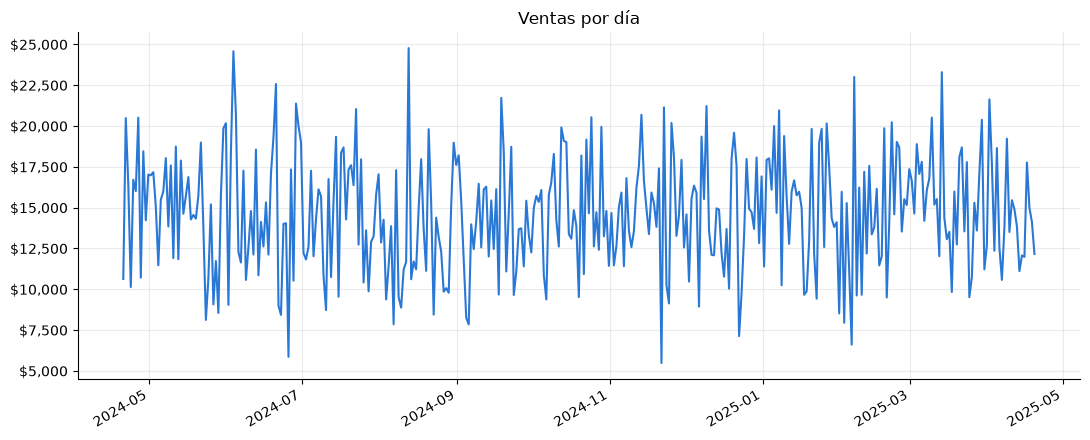

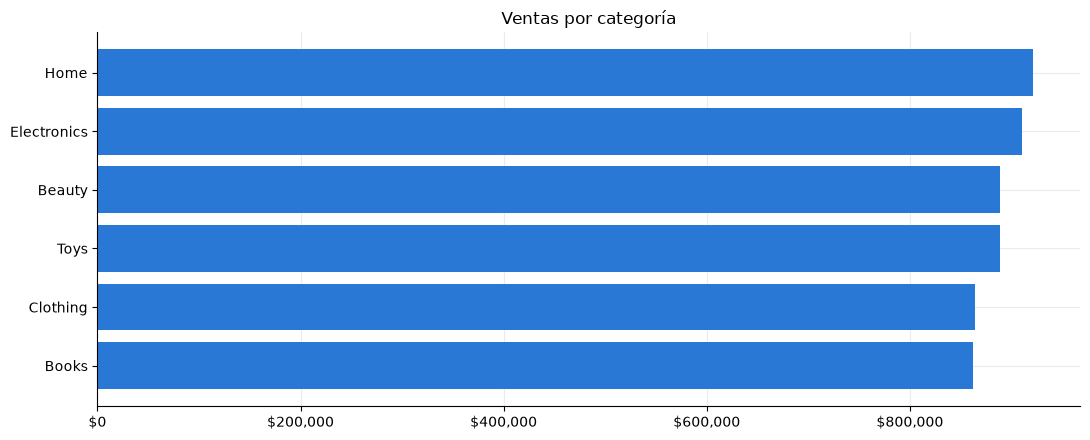

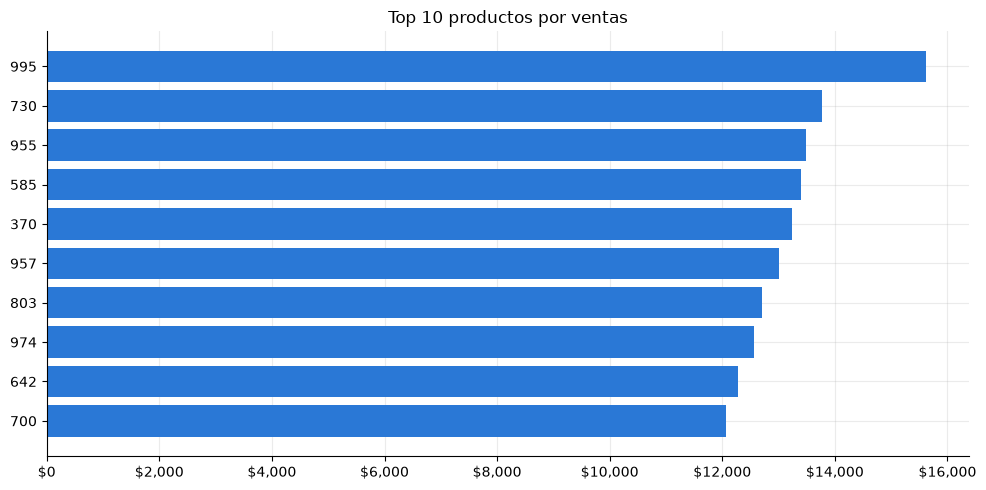

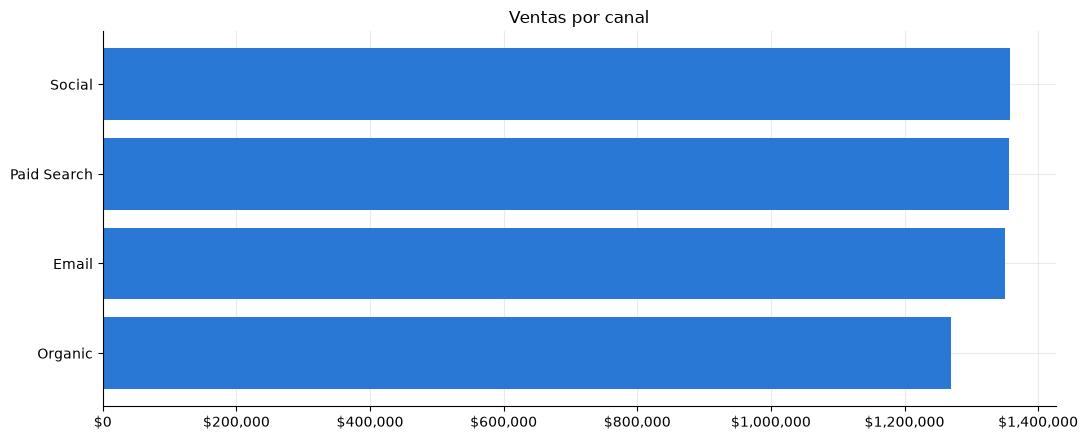

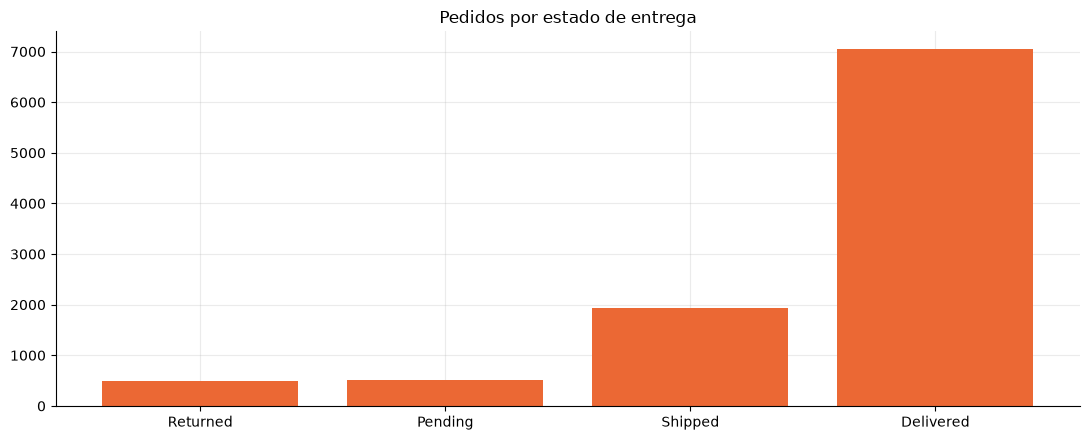

In [97]:
AE = AnalisisEcommerce(datos_base)
GE = GraficosEcommerce(AE)
GB.ventas_por_dia()
GB.categorias()
GB.top_productos(10)
GE.canales()
GE.entregas()


---
# PARTE 4 - Preguntas de negocio y resultados

Las cuatro preguntas se responden con agrupaciones y calculos especificos. Cada tabla tiene un nivel de detalle definido, se interpreta y se exporta automaticamente a CSV. La rentabilidad no se afirma porque no hay costos.

In [98]:
SALIDA_PUNTO_4 = ROOT / "src" / "sincronicas" / "datos" / "resultados_punto_4"
SALIDA_PUNTO_4.mkdir(parents=True, exist_ok=True)

enriquecedor = EnriquecedorEcommerce()
datos = enriquecedor.enriquecer(datos_base)
datos.to_csv(SALIDA_PUNTO_4 / "dataset_ecommerce_preparado.csv", index=False, encoding="utf-8-sig")
Reportes().guardar_reporte(datos, SALIDA_PUNTO_4 / "resumen_dataset_ecommerce.txt")
print(f"Dataset preparado y enriquecido: {datos.shape[0]:,} filas y {datos.shape[1]} columnas")

Dataset preparado y enriquecido: 10,000 filas y 29 columnas


## 4.1 Que categorias aportan mas ventas?

**Nivel de detalle:** categoria. La tabla incluye pedidos, unidades, valor vendido y participacion. Es util para priorizar inventario y promociones. **Limitacion:** ventas no equivale a rentabilidad porque no se conocen costos ni margenes.

In [99]:
tabla_categorias = (datos.groupby("category", observed=True)
    .agg(pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_categorias["participacion_ventas"] = tabla_categorias["ventas"] / tabla_categorias["ventas"].sum()
assert abs(tabla_categorias["participacion_ventas"].sum() - 1) < 1e-9
tabla_categorias.to_csv(SALIDA_PUNTO_4 / "pregunta_1_categorias.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_categorias))
print(f"Respuesta: {tabla_categorias.iloc[0]['category']} lidera con ${tabla_categorias.iloc[0]['ventas']:,.2f} ({tabla_categorias.iloc[0]['participacion_ventas']:.1%}).")

,category,pedidos,unidades,ventas,participacion_ventas
4,Home,"1,713","3,696","$921,394.85",$0.17
3,Electronics,"1,694","3,586","$910,153.11",$0.17
0,Beauty,"1,682","3,617","$888,823.19",$0.17
5,Toys,"1,666","3,552","$888,447.70",$0.17
2,Clothing,"1,620","3,392","$863,629.45",$0.16
1,Books,"1,625","3,404","$862,484.56",$0.16


Respuesta: Home lidera con $921,394.85 (17.3%).


## 4.2 Que productos aportan mas ventas?

**Nivel de detalle:** producto y categoria. La tabla permite priorizar disponibilidad y campa?as. **Limitacion:** `product_id` es un identificador y no un nombre comercial; tampoco existen costos.

In [100]:
tabla_productos = (datos.groupby(["product_id", "category"], observed=True)
    .agg(pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_productos["participacion_ventas"] = tabla_productos["ventas"] / tabla_productos["ventas"].sum()
assert abs(tabla_productos["participacion_ventas"].sum() - 1) < 1e-9
tabla_productos.to_csv(SALIDA_PUNTO_4 / "pregunta_2_productos.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_productos.head(20)))
print(f"Respuesta: el producto {tabla_productos.iloc[0]['product_id']} lidera con ${tabla_productos.iloc[0]['ventas']:,.2f}.")

,product_id,category,pedidos,unidades,ventas,participacion_ventas
4837,995,Electronics,5,18,"$7,048.14",$0.00
2825,585,Beauty,6,19,"$6,749.61",$0.00
4639,955,Beauty,7,15,"$6,370.36",$0.00
223,43,Clothing,3,12,"$5,641.68",$0.00
3962,812,Home,5,14,"$5,618.82",$0.00
4654,957,Toys,7,17,"$5,545.54",$0.00
4060,832,Beauty,3,14,"$5,450.80",$0.00
4034,827,Beauty,6,19,"$5,450.64",$0.00
502,102,Home,3,13,"$5,402.78",$0.00
1935,398,Home,9,24,"$5,395.48",$0.00


Respuesta: el producto 995 lidera con $7,048.14.


## 4.3 Que combinacion de canal y segmento genera mas ventas?

**Nivel de detalle:** canal y segmento. Permite comparar contribuciones comerciales. **Limitacion:** no mide eficiencia publicitaria porque no incluye inversion, conversiones ni margen.

In [101]:
tabla_canales_segmentos = (datos.groupby(["channel", "customer_segment"], observed=True)
    .agg(clientes=("customer_id", "nunique"), pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_canales_segmentos["participacion_ventas"] = tabla_canales_segmentos["ventas"] / tabla_canales_segmentos["ventas"].sum()
assert abs(tabla_canales_segmentos["participacion_ventas"].sum() - 1) < 1e-9
tabla_canales_segmentos.to_csv(SALIDA_PUNTO_4 / "pregunta_3_canales_segmentos.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_canales_segmentos))
primero = tabla_canales_segmentos.iloc[0]
print(f"Respuesta: {primero['channel']} en {primero['customer_segment']} concentra ${primero['ventas']:,.2f} ({primero['participacion_ventas']:.1%}).")

,channel,customer_segment,clientes,pedidos,unidades,ventas,participacion_ventas
11,Social,VIP,530,"1,312","2,797","$693,011.14",$0.13
2,Email,VIP,531,"1,300","2,769","$687,331.38",$0.13
8,Paid Search,VIP,509,"1,279","2,703","$672,350.54",$0.13
5,Organic,VIP,517,"1,258","2,656","$669,994.04",$0.13
7,Paid Search,Returning,860,"1,101","2,372","$609,039.06",$0.11
10,Social,Returning,852,"1,105","2,365","$589,405.59",$0.11
1,Email,Returning,799,"1,027","2,273","$578,479.08",$0.11
4,Organic,Returning,801,"1,052","2,122","$539,482.91",$0.10
0,Email,New,147,147,331,"$83,924.17",$0.02
9,Social,New,149,149,308,"$75,980.57",$0.01


Respuesta: Social en VIP concentra $693,011.14 (13.0%).


## 4.4 Como se comportan las entregas y cuales requieren atencion?

**Nivel de detalle:** estado de entrega. Incluye pedidos, ventas, dias promedio de envio y porcentaje. **Limitacion:** no existe fecha prometida ni fecha real de entrega para medir cumplimiento exacto.

In [102]:
tabla_entregas = (datos.groupby("delivery_status", observed=True)
    .agg(pedidos=("order_id", "nunique"), ventas=("order_value", "sum"), dias_envio_promedio=("shipping_days", "mean"))
    .reset_index().sort_values("pedidos", ascending=False))
tabla_entregas["porcentaje_pedidos"] = tabla_entregas["pedidos"] / tabla_entregas["pedidos"].sum()
assert abs(tabla_entregas["porcentaje_pedidos"].sum() - 1) < 1e-9
assert tabla_entregas["pedidos"].sum() == datos["order_id"].nunique()
tabla_entregas.to_csv(SALIDA_PUNTO_4 / "pregunta_4_entregas.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_entregas))
print(f"Respuesta: el estado mas frecuente es {tabla_entregas.iloc[0]['delivery_status']} con {tabla_entregas.iloc[0]['pedidos']:,} pedidos ({tabla_entregas.iloc[0]['porcentaje_pedidos']:.1%}).")

,delivery_status,pedidos,ventas,dias_envio_promedio,porcentaje_pedidos
0,Delivered,"7,047","$3,735,009.93",4.02,0.70
3,Shipped,"1,938","$1,059,166.13",3.96,0.19
1,Pending,513,"$278,573.19",4.04,0.05
2,Returned,502,"$262,183.61",3.99,0.05


Respuesta: el estado mas frecuente es Delivered con 7,047 pedidos (70.5%).


## 4.5 Exportaciones y verificacion final

El dataset transformado, las cuatro tablas y el resumen descriptivo TXT quedan disponibles para reutilizarlos en visualizaciones. El TXT se regenera en cada ejecucion e incluye filas, columnas, tipos, nulos y estadisticas descriptivas.

In [103]:
archivos_punto_4 = sorted(p.name for p in SALIDA_PUNTO_4.iterdir() if p.is_file())
for nombre in archivos_punto_4:
    print(f"- {nombre}")
assert (SALIDA_PUNTO_4 / "dataset_ecommerce_preparado.csv").exists()
assert (SALIDA_PUNTO_4 / "resumen_dataset_ecommerce.txt").exists()
assert len([n for n in archivos_punto_4 if n.startswith("pregunta_") and n.endswith(".csv")]) == 4
print("Verificacion completada: tablas y totales consistentes.")

- dataset_ecommerce_preparado.csv
- pregunta_1_categorias.csv
- pregunta_2_productos.csv
- pregunta_3_canales_segmentos.csv
- pregunta_4_entregas.csv
- resumen_dataset_ecommerce.txt
Verificacion completada: tablas y totales consistentes.
